<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/selfsupervised_demos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# References

[Course Webpage](https://sites.google.com/view/berkeley-cs294-158-sp20/home)

[1] Pathak, Deepak, et al. "Context encoders: Feature learning by inpainting." Proceedings of the IEEE conference on computer vision and pattern recognition. 2016.

[2] Gidaris, Spyros, Praveer Singh, and Nikos Komodakis. "Unsupervised representation learning by predicting image rotations." arXiv preprint arXiv:1803.07728 (2018).

[3] Chen, Ting, et al. "A simple framework for contrastive learning of visual representations." arXiv preprint arXiv:2002.05709 (2020).

[4] Noroozi, Mehdi, and Paolo Favaro. "Unsupervised learning of visual representations by solving jigsaw puzzles." European Conference on Computer Vision. Springer, Cham, 2016.

[5] Wang, Xiaolong, Allan Jabri, and Alexei A. Efros. "Learning correspondence from the cycle-consistency of time." Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition. 2019.

[6] Oord, Aaron van den, Yazhe Li, and Oriol Vinyals. "Representation learning with contrastive predictive coding." arXiv preprint arXiv:1807.03748 (2018).

[7] Hénaff, Olivier J., et al. "Data-efficient image recognition with contrastive predictive coding." arXiv preprint arXiv:1905.09272 (2019).

[8] Tian, Yonglong, Dilip Krishnan, and Phillip Isola. "Contrastive multiview coding." arXiv preprint arXiv:1906.05849 (2019).

[9] He, Kaiming, et al. "Momentum contrast for unsupervised visual representation learning." arXiv preprint arXiv:1911.05722 (2019).

[10] Doersch, Carl, Abhinav Gupta, and Alexei A. Efros. "Unsupervised visual representation learning by context prediction." Proceedings of the IEEE International Conference on Computer Vision. 2015.

[11] Ronneberger, Olaf, Philipp Fischer, and Thomas Brox. "U-net: Convolutional networks for biomedical image segmentation." International Conference on Medical image computing and computer-assisted intervention. Springer, Cham, 2015.

# Getting Started
Go to **Runtime -> Change runtime type** and make sure **Hardward accelerator** is set to **GPU**

In [1]:
!if [ -d cs294-158-ssl ]; then rm -Rf cs294-158-ssl; fi
!git clone https://github.com/ckurtz/cs294-158-ssl
!pip install cs294-158-ssl/

import os
os.chdir('cs294-158-ssl')

Cloning into 'cs294-158-ssl'...
remote: Enumerating objects: 615, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 615 (delta 92), reused 90 (delta 90), pack-reused 517 (from 1)
Receiving objects: 100% (615/615), 3.10 MiB | 15.57 MiB/s, done.
Resolving deltas: 100% (442/442), done.
Processing ./cs294-158-ssl
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepul_helper: filename=deepul_helper-0.1.0-py3-none-any.whl size=25330 sha256=e53f16e847731b40bac3d7c103811175d6756c079c0fba7e60b24ee116236572
  Stored in directory: /tmp/pip-ephem-wheel-cache-r8elhafe/wheels/41/c6/8a/07e8f4374eeb04ae58407716e4acc5040e23fe93acd34d166b
Successfully built deepul_helper


Run the cells below to download the necessary pretrained models. It should take a few minutes.

In [2]:
!wget https://camille-kurtz.com/teaching/data.zip
!unzip -qq data.zip
!rm data.zip

--2026-10-30 18:08:11--  https://camille-kurtz.com/teaching/data.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4227668031 (3.9G) [application/zip]
Saving to: ‘data.zip’

data.zip            100%[===================>]   3.94G  9.74MB/s    in 5m 32s  

2026-10-30 18:13:45 (12.1 MB/s) - ‘data.zip’ saved [4227668031/4227668031]



In [3]:
!wget https://camille-kurtz.com/teaching/results.zip
!unzip -qq results.zip
!rm results.zip

--2026-10-30 18:14:20--  https://camille-kurtz.com/teaching/results.zip
Resolving camille-kurtz.com (camille-kurtz.com)... 213.186.33.3
Connecting to camille-kurtz.com (camille-kurtz.com)|213.186.33.3|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2636425194 (2.5G) [application/zip]
Saving to: ‘results.zip’

results.zip         100%[===================>]   2.46G  10.1MB/s    in 4m 38s  

2026-10-30 18:18:59 (9.04 MB/s) - ‘results.zip’ saved [2636425194/2636425194]



The models and demos shown were pre-trained. The code used for all the demos can be found in the github repo [here](https://github.com/wilson1yan/cs294-158-ssl). Follow the README to train models on CIFAR10 or ImageNet.

# Self-Supervised Learning Tasks
Self-supervised learning is a rapidly growing field, its success largely accelerated by growing compute and the vast amount of unlabeled data available for training. The hope is that by pretraining on specially designed self-supervised tasks, the models would be able to learn semantically meaningful representations to be used for downstream tasks. In the following demos, we will look at a few examples of these self-supervised tasks.

In [4]:
from deepul_helper.demos import load_model_and_data, evaluate_accuracy, display_nearest_neighbors, show_context_encoder_inpainting

%matplotlib inline

## Demo 1: Context Encoder [[1]](https://arxiv.org/abs/1604.07379)

The context encoder structures its self-supervised learning task by inpainting masked images. For example, the figure below shows different masking shapes, such as center masking, random block masking, and segmentation masking. Note that segmentation masking (c) is not purely self-supervised since we would need to train a image segmentation model which requires labels. However, the other two masking schemes (a) and (b) and purely self-supervised.

![](https://drive.google.com/uc?id=1fhzkULYTtyMGUUF2n9dlPayJSdcY5pRv)

More formally, the context encoder optimizes the following reconstruction loss:
$$\mathcal{L}_{rec} = \left\Vert \hat{M} \odot (x - F((1 - \hat{M})\odot x)) \right\Vert^2_2$$
where $\hat{M}$ is the masked region, $x$ is the image, and $F$ is the context encoder that tries to reconstruct the masked portion. In addition to the reconstruction loss, the paper introduces an adversarial loss that encourages more realistic inpaintings.
$$L_{adv} = \max_D \mathbb{E}_{x\in \chi} [\log(D(x)) + \log(1 - D(F((1-\hat{M})\odot x)))]$$
However, this demo does not use the adversarial portion of the loss.

### Example Code

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ContextEncoder(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes):
        super().__init__()
        input_channels = 3

        self.latent_dim = 4000

        # Encodes the masked image
        self.encoder = nn.Sequential(
            # 128 x 128 Input
            nn.Conv2d(input_channels, 64, 4, stride=2, padding=1), # 64 x 64
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 64, 4, stride=2, padding=1), # 32 x 32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), # 16 x 16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), # 8 x 8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(256, 512, 4, stride=2, padding=1), # 4 x 4
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(512, self.latent_dim, 4) # 1 x 1
        )

        # Only reconstructs the masked part of the image and not the whole image
        self.decoder = nn.Sequential(
           nn.BatchNorm2d(self.latent_dim),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(self.latent_dim, 512, 4, stride=1, padding=0), # 4 x 4
           nn.BatchNorm2d(512),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(512, 256, 4, stride=2, padding=1), # 8 x 8
           nn.BatchNorm2d(256),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), # 16 x 16
           nn.BatchNorm2d(128),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), # 32 x 32
           nn.BatchNorm2d(64),
           nn.ReLU(inplace=True),
           nn.ConvTranspose2d(64, input_channels, 4, stride=2, padding=1), # 64 x 64
           nn.Tanh()
        )

        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        classifier = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(self.latent_dim, affine=False),
            nn.Linear(self.latent_dim, self.n_classes)
        )
        return classifier

    def forward(self, images):
        # Extract a 64 x 64 center from 128 x 128 image
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        # Mask out a 64 x 64 center with slight overlap
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        return dict(Loss=F.mse_loss(center_recon, images_center)), torch.flatten(z, 1)

    def encode(self, images):
        images_masked = images
        images_masked[:, 0, 32+4:32+64-4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64-4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64-4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0
        return self.encoder(images_masked)

    def reconstruct(self, images):
        images_center = images[:, :, 32:32+64, 32:32+64].clone()
        images_masked = images.clone()
        images_masked[:, 0, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 117.0/255.0 - 1.0
        images_masked[:, 1, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 104.0/255.0 - 1.0
        images_masked[:, 2, 32+4:32+64 - 4, 32+4:32+64-4] = 2 * 123.0/255.0 - 1.0

        z = self.encoder(images_masked)
        center_recon = self.decoder(z)

        images_recon = images_masked.clone()
        images_recon[:, :, 32:32+64, 32:32+64] = center_recon
        return images_masked, images_recon


### Inpainting Examples
For each pair of images, the left image is the masked input and the right the inpainted reconstruction.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


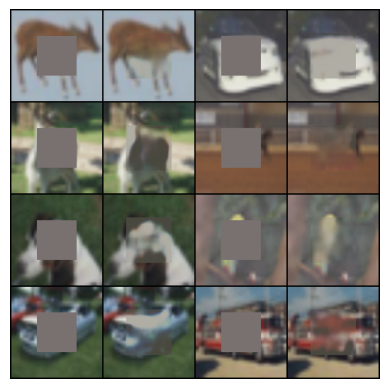

In [ ]:
show_context_encoder_inpainting()

### Linear Classification
By design the model architecture is an encoder -> decoder module. We can use the bottleneck layer as our learned representation. Below, we show linear classification accuracy results on CIFAR10 using the learned representations.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('context_encoder')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 53.236, Top 5 Accuracy: 94.094

Test Set
Top 1 Accuracy: 45.77, Top 5 Accuracy: 90.29



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


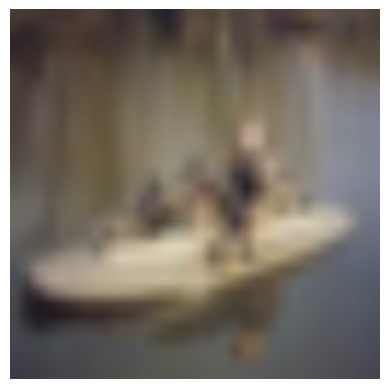

Top 16 Nearest Neighbors (in latent space)


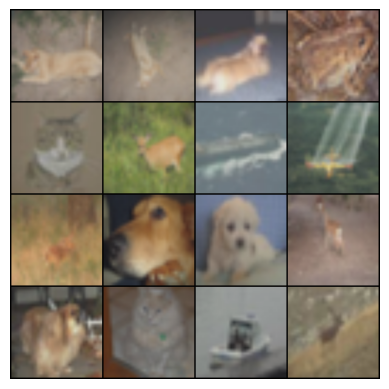

Image 2


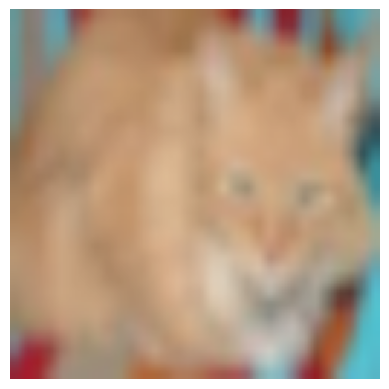

Top 16 Nearest Neighbors (in latent space)


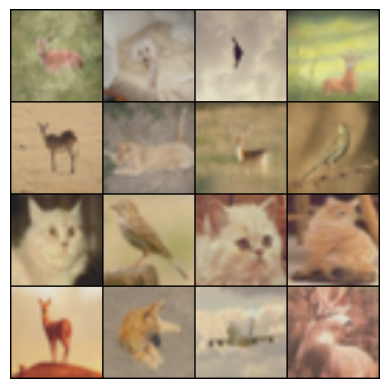

Image 3


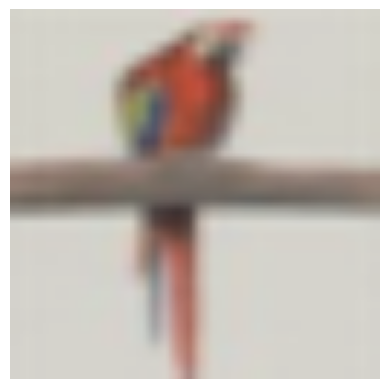

Top 16 Nearest Neighbors (in latent space)


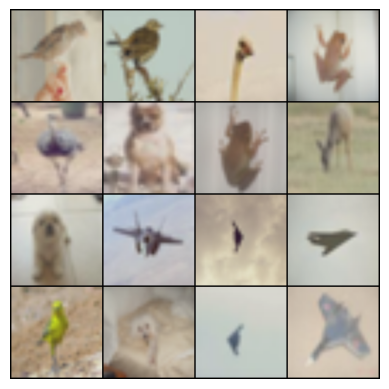

Image 4


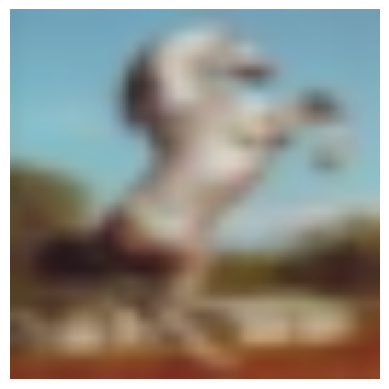

Top 16 Nearest Neighbors (in latent space)


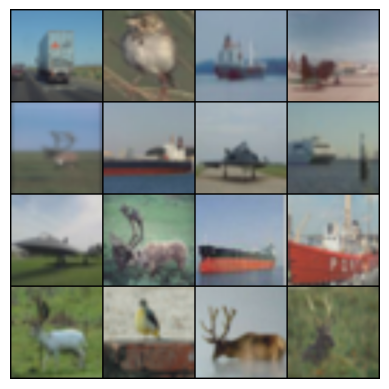

In [ ]:
display_nearest_neighbors('context_encoder', model, test_loader)

## Demo 2: Rotation Prediction [[2]](https://arxiv.org/abs/1803.07728)

In this paper, the authors show that accurately predicting the degrees of rotation in images is a self-supervised learning task that learns good representations for downstream tasks.

![](https://drive.google.com/uc?id=1eHXLH-N_6uMGRzdf1Wjnga26qlS5-FRv)

More specifically, the authors showed that training a common CNN architecture (AlexNet, ResNet) on the rotation task learns semantically interpretable convolutional masks similar to those learned in supervised learning.

### Example Code

In [6]:
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


class RotationPrediction(nn.Module):
    metrics = ['Loss', 'Acc1']
    metrics_fmt = [':.4e', ':6.2f']

    def __init__(self, dataset, n_classes):
        super().__init__()
        if dataset == 'cifar10':
            self.model = NetworkInNetwork()
            self.latent_dim = 192 * 8 * 8
            self.feat_layer = 'conv2'
        elif 'imagenet' in dataset:
            self.model = AlexNet()
            self.latent_dim = 256 * 13 * 13
            self.feat_layer = 'conv5'
        else:
            raise Exception('Unsupported dataset:', dataset)
        self.dataset = dataset
        self.n_classes = n_classes

    def construct_classifier(self):
        if self.dataset == 'cifar10':
            classifier = nn.Sequential(
                nn.Flatten(),
                nn.BatchNorm1d(self.latent_dim, affine=False),
                nn.Linear(self.latent_dim, self.n_classes)
            )
        elif 'imagenet' in self.dataset:
            classifier = nn.Sequential(
                nn.AdaptiveMaxPool2d((6, 6)),
                nn.BatchNorm2d(256, affine=False),
                nn.Flatten(),
                nn.Linear(256 * 6 * 6, self.n_classes)
            )
        else:
            raise Exception('Unsupported dataset:', dataset)
        return classifier

    def forward(self, images):
        batch_size = images.shape[0]
        images, targets = self._preprocess(images)
        targets = targets.to(images.get_device())

        logits, zs = self.model(images, out_feat_keys=('classifier', self.feat_layer))
        loss = F.cross_entropy(logits, targets)

        pred = logits.argmax(dim=-1)
        correct = pred.eq(targets).float().sum()
        acc = correct / targets.shape[0] * 100.

        return dict(Loss=loss, Acc1=acc), zs[:batch_size]

    def encode(self, images):
        zs = self.model(images, out_feat_keys=(self.feat_layer,))
        return zs

    def _preprocess(self, images):
        batch_size = images.shape[0]
        images_90 = torch.flip(images.transpose(2, 3), (2,))
        images_180 = torch.flip(images, (2, 3))
        images_270 = torch.flip(images, (2,)).transpose(2, 3)
        images_batch = torch.cat((images, images_90, images_180, images_270), dim=0)
        targets = torch.arange(4).long().repeat(batch_size)
        targets = targets.view(batch_size, 4).transpose(0, 1)
        targets = targets.contiguous().view(-1)
        return images_batch, targets

### Linear Classification
We can use the feature maps in the later convolutional layers of the pretrained model as our learned representation for linear classification.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('rotation')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 79.274, Top 5 Accuracy: 99.106

Test Set
Top 1 Accuracy: 79.91, Top 5 Accuracy: 99.12



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


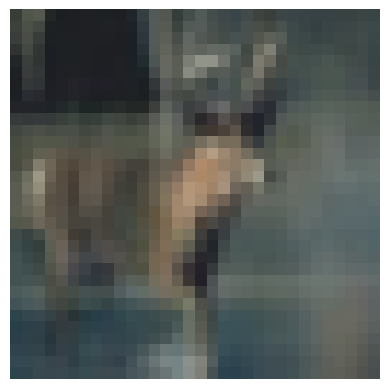

Top 16 Nearest Neighbors (in latent space)


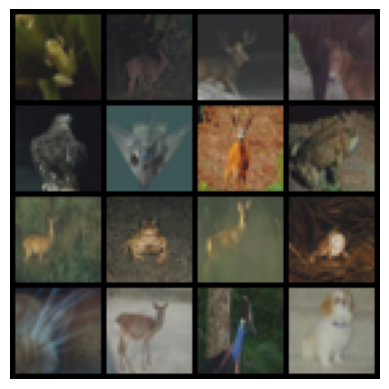

Image 2


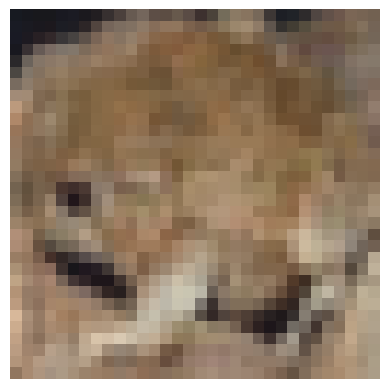

Top 16 Nearest Neighbors (in latent space)


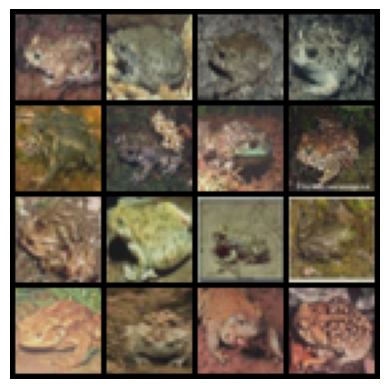

Image 3


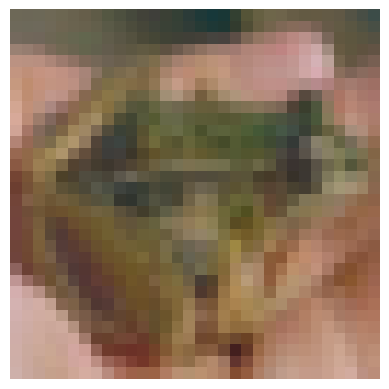

Top 16 Nearest Neighbors (in latent space)


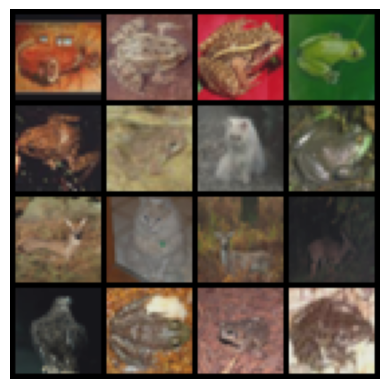

Image 4


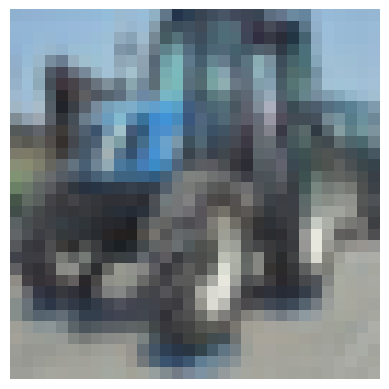

Top 16 Nearest Neighbors (in latent space)


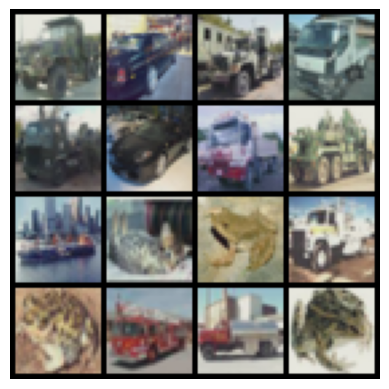

In [ ]:
display_nearest_neighbors('rotation', model, test_loader)

## Demo 3: SimCLR [[3]](https://arxiv.org/abs/2002.05709)

SimCLR is a contrastive learning framework to learn strong visual representations. An image $x$ is processed using data augmentation to produce two variants $x_i$ and $x_j$ which are both fed into encoder $f$ (a CNN) and projection head $g$ (a small MLP). The models optimize a contrastive loss to maximally align projected latents $z_i, z_j$. We consider $x_i, x_j$ as a positive pair, and any other $x_i, x_k$ pairs (i.e. different images in the same batch) are negative pairs. A visual diagram of the training procedure is shown below (from the paper).

![](https://drive.google.com/uc?id=1XW1uIkUTMSa0DZncivSYXzM5gA5FIhF6)

More formally, the loss between positive example $z_i, z_j$ is:
$$\ell_{i,j} = -\log{\frac{\exp(\text{sim}(z_i, z_j)/\tau)}{\sum_{k=1}^{2N}\mathbb{1}_{[k\neq i]}\exp(\text{sim}(z_i, z_k)/\tau)}}$$
where $\text{sim}(z_i, z_j) = z_i^Tz_j / (\left\Vert z_i \right\Vert \left\Vert z_j \right\Vert)$. The loss function can also be interpreted as a standard cross entropy loss to classify positive samples where logits are constructed using a given similarity function.

Note: A common idea in contrastive learning methods is that a larger batch means more negative samples. Therefore, these methods usually benefit the most from large-batch learning compared to other self-supervised learning tasks.

### Example Code

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from deepul_helper.resnet import resnet_v1
from deepul_helper.batch_norm import SyncBatchNorm, BatchNorm1d

# Some code adapted from https://github.com/sthalles/SimCLR
class SimCLR(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, dataset, n_classes, dist=None):
        super().__init__()
        self.temperature = 0.5
        self.projection_dim = 128

        if dataset == 'cifar10':
            resnet = resnet_v1((3, 32, 32), 50, 1, cifar_stem=True)
            resnet = SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048
        elif 'imagenet' in dataset:
            resnet = resnet_v1((3, 128, 128), 50, 1, cifar_stem=False)
            if dist is not None:
                resnet = nn.SyncBatchNorm.convert_sync_batchnorm(resnet)
            self.resnet = resnet
            self.latent_dim = 2048

        self.proj = nn.Sequential(
            nn.Linear(self.latent_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim),
            nn.ReLU(inplace=True),
            nn.Linear(self.projection_dim, self.projection_dim, bias=False),
            BatchNorm1d(self.projection_dim, center=False)
        )

        self.dataset = dataset
        self.n_classes = n_classes
        self.dist = dist

    def construct_classifier(self):
        return nn.Sequential(nn.Linear(self.latent_dim, self.n_classes))

    def forward(self, images):
        n = images[0].shape[0]
        xi, xj = images
        hi, hj = self.encode(xi), self.encode(xj) # (N, latent_dim)
        zi, zj = self.proj(hi), self.proj(hj) # (N, projection_dim)
        zi, zj = F.normalize(zi), F.normalize(zj)

        # Each training example has 2N - 2 negative samples
        # 2N total samples, but exclude the current and positive sample

        if self.dist is None:
            zis = [zi]
            zjs = [zj]
        else:
            zis = [torch.zeros_like(zi) for _ in range(self.dist.get_world_size())]
            zjs = [torch.zeros_like(zj) for _ in range(self.dist.get_world_size())]

            self.dist.all_gather(zis, zi)
            self.dist.all_gather(zjs, zj)

        z1 = torch.cat((zi, zj), dim=0) # (2N, projection_dim)
        z2 = torch.cat(zis + zjs, dim=0) # (2N * n_gpus, projection_dim)

        sim_matrix = torch.mm(z1, z2.t()) # (2N, 2N * n_gpus)
        sim_matrix = sim_matrix / self.temperature
        # Mask out same-sample terms
        n_gpus = 1 if self.dist is None else self.dist.get_world_size()
        rank = 0 if self.dist is None else self.dist.get_rank()
        sim_matrix[torch.arange(n), torch.arange(rank*n, (rank+1)*n)]  = -float('inf')
        sim_matrix[torch.arange(n, 2*n), torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n)] = -float('inf')

        targets = torch.cat((torch.arange((n_gpus+rank)*n, (n_gpus+rank+1)*n),
                             torch.arange(rank*n, (rank+1)*n)), dim=0)
        targets = targets.to(sim_matrix.get_device()).long()

        loss = F.cross_entropy(sim_matrix, targets, reduction='sum')
        loss = loss / n
        return dict(Loss=loss), hi

    def encode(self, images):
        return self.resnet(images[0])

    def get_features(self, images):
        return self.resnet.get_features(images)


### Linear Classification
We can use the encoded vector $h_i$ as our latent representation.

In [ ]:
model, linear_classifier, train_loader, test_loader = load_model_and_data('simclr')
evaluate_accuracy(model, linear_classifier, train_loader, test_loader)

Train Set
Top 1 Accuracy: 90.112, Top 5 Accuracy: 99.468

Test Set
Top 1 Accuracy: 92.84, Top 5 Accuracy: 99.86



### Nearest Neighbors
Another way to evaluate our learned representation is to look at nearest neighbors to random encoded images in latent space.

Image 1


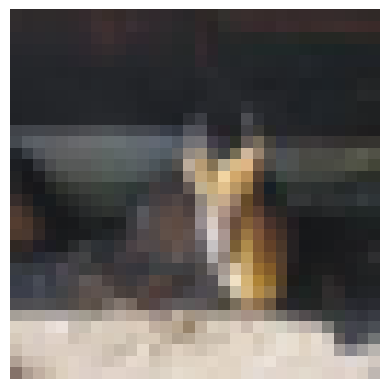

Top 16 Nearest Neighbors (in latent space)


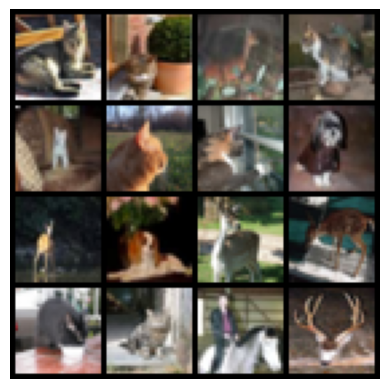

Image 2


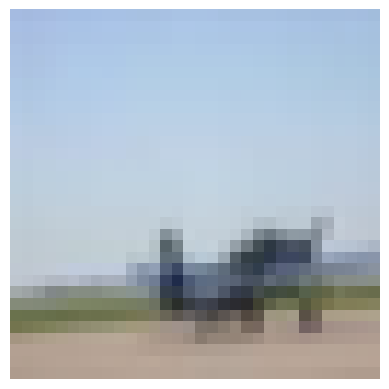

Top 16 Nearest Neighbors (in latent space)


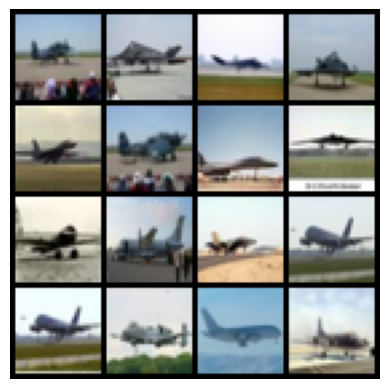

Image 3


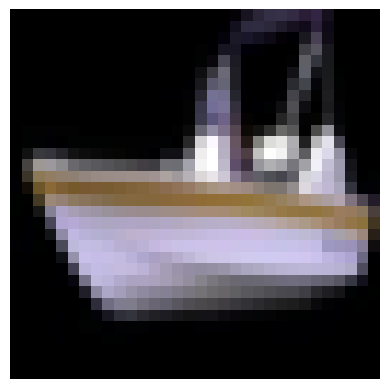

Top 16 Nearest Neighbors (in latent space)


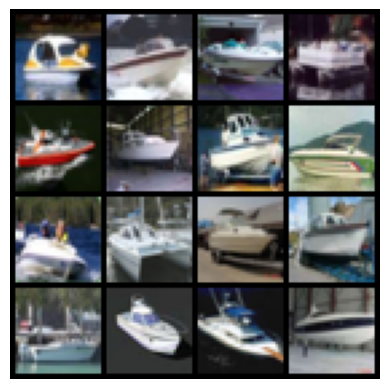

Image 4


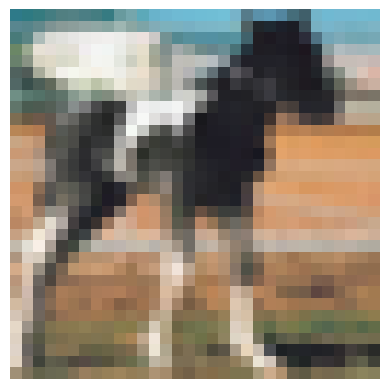

Top 16 Nearest Neighbors (in latent space)


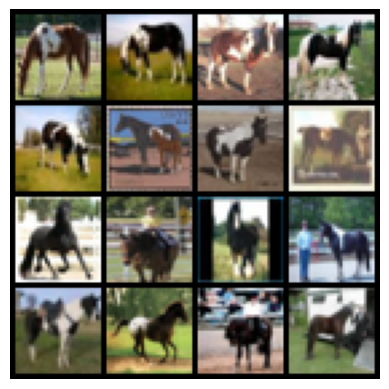

In [ ]:
display_nearest_neighbors('simclr', model, test_loader)

# Comparison on CIFAR10


Évaluation : Context Encoder


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()



Évaluation : Rotation Prediction

Évaluation : SimCLR

Comparaison des performances sur CIFAR-10 :

             Modèle  Tâche prétexte  Accuracy train top1 (%)  Accuracy train top5 (%)  Accuracy test top1 (%)  Accuracy test top5 (%)
             SimCLR          simclr                    90.01                    99.44                   92.84                   99.86
Rotation Prediction        rotation                    79.46                    99.13                   79.91                   99.12
    Context Encoder context_encoder                    53.24                    94.09                   45.77                   90.29


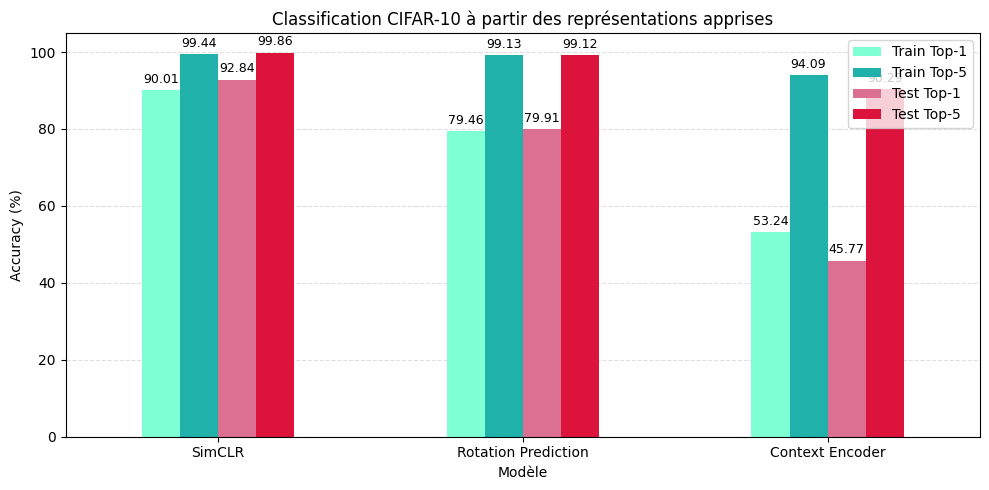

In [ ]:
import gc
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

from deepul_helper.demos import load_model_and_data, evaluate_classifier


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("comparaison_resultats")
OUTPUT_DIR.mkdir(exist_ok=True)

MODELES = [
    ("context_encoder", "Context Encoder"),
    ("rotation", "Rotation Prediction"),
    ("simclr", "SimCLR")
]

def comparer_modeles():
    resultats = []

    for task, nom in MODELES:
        print(f"\nÉvaluation : {nom}")

        model, classifier, train_loader, test_loader=load_model_and_data(task)
        model = model.to(DEVICE)
        classifier = classifier.to(DEVICE)

        train_acc1, train_acc5 = evaluate_classifier(model, classifier, train_loader)
        test_acc1, test_acc5 = evaluate_classifier(model, classifier, test_loader)


        resultats.append({
            "Modèle": nom,
            "Tâche prétexte": task,
            "Accuracy train top1 (%)": train_acc1,
            "Accuracy train top5 (%)": train_acc5,
            "Accuracy test top1 (%)": test_acc1,
            "Accuracy test top5 (%)": test_acc5
        })

        del model, classifier, train_loader, test_loader
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

    return (
        pd.DataFrame(resultats)
        .sort_values("Accuracy test top1 (%)", ascending=False)
        .reset_index(drop=True)
    )


#comparer
df = comparer_modeles()

#tableau
print("\nComparaison des performances sur CIFAR-10 :\n")
print(df.round(2).to_string(index=False))
df.to_csv(OUTPUT_DIR / "comparaison_cifar10.csv", index=False)

#graph
ax = df.set_index("Modèle")[
    ["Accuracy train top1 (%)", "Accuracy train top5 (%)", "Accuracy test top1 (%)",
     "Accuracy test top5 (%)"]
].plot.bar(
    figsize=(10, 5),
    color=["aquamarine", "lightseagreen", "palevioletred", "crimson"],
    rot=0,
)

ax.set_title("Classification CIFAR-10 à partir des représentations apprises")
ax.set_xlabel("Modèle")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(["Train Top-1", "Train Top-5", "Test Top-1", "Test Top-5"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparaison_cifar10.png", dpi=200)
plt.show()

# Comparison on CIFAR100 dataset


In [8]:
import gc
from pathlib import Path

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR100
from deepul_helper.demos import load_model_and_data



def get_transforms_cifar100(dataset, task, train=True):
    transform = None
    if task == 'context_encoder':
        transform = transforms.Compose([transforms.Resize(128),
                transforms.ToTensor(),
                transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
        ])

    elif task == 'rotation':
        if train:
            transform = transforms.Compose([
                transforms.RandomCrop(32, padding=4),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
            ])
        else:
          transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
            ])


    elif task == 'simclr':
      if train:
            transform = transforms.Compose([
                transforms.RandomResizedCrop(32),
                transforms.RandomHorizontalFlip(p=0.5),
                transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
                transforms.RandomGrayscale(p=0.2),
                transforms.ToTensor(),
                transforms.Normalize([0.4914, 0.4822, 0.4465], [0.2023, 0.1994, 0.2010])
            ])
      else:
            transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize([0.4914, 0.4822, 0.4465], [0.2023, 0.1994, 0.2010])
            ])

      transform = SimCLRDataTransform(transform)

    else:
        raise Exception('Invalid task:', task)

    return transform




Context Encoder


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
100%|██████████| 169M/169M [26:13<00:00, 107kB/s]


  Epoch 01/20 - loss: 3.8540
  Epoch 02/20 - loss: 3.2747
  Epoch 03/20 - loss: 3.0141
  Epoch 04/20 - loss: 2.8132
  Epoch 05/20 - loss: 2.6659
  Epoch 06/20 - loss: 2.5342
  Epoch 07/20 - loss: 2.4133
  Epoch 08/20 - loss: 2.3204
  Epoch 09/20 - loss: 2.2296
  Epoch 10/20 - loss: 2.1532
  Epoch 11/20 - loss: 2.0656
  Epoch 12/20 - loss: 2.0133
  Epoch 13/20 - loss: 1.9379
  Epoch 14/20 - loss: 1.8854
  Epoch 15/20 - loss: 1.8221
  Epoch 16/20 - loss: 1.7745
  Epoch 17/20 - loss: 1.7180
  Epoch 18/20 - loss: 1.6855
  Epoch 19/20 - loss: 1.6378
  Epoch 20/20 - loss: 1.5876
  Train accuracy: 64.95%
  Test accuracy:  22.98%

Rotation Prediction
  Epoch 01/20 - loss: 2.9078
  Epoch 02/20 - loss: 0.9618
  Epoch 03/20 - loss: 0.4503
  Epoch 04/20 - loss: 0.2520
  Epoch 05/20 - loss: 0.1859
  Epoch 06/20 - loss: 0.1900
  Epoch 07/20 - loss: 0.2295
  Epoch 08/20 - loss: 0.2895
  Epoch 09/20 - loss: 0.2614
  Epoch 10/20 - loss: 0.2125
  Epoch 11/20 - loss: 0.1749
  Epoch 12/20 - loss: 0.1746
 

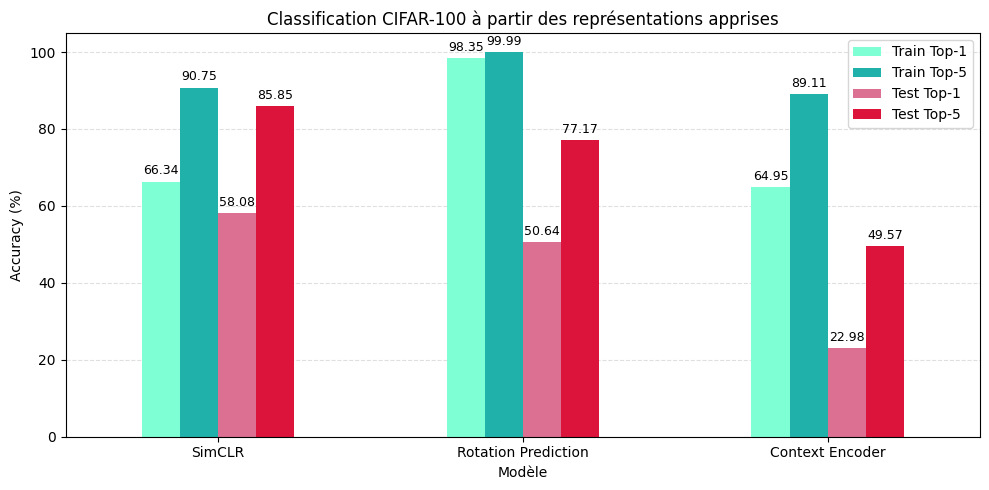

In [9]:
import gc
from pathlib import Path

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision.datasets import CIFAR100
from deepul_helper.demos import load_model_and_data, evaluate_classifier


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 1e-3
SEED = 42

OUTPUT_DIR = Path("comparaison_cifar100")
OUTPUT_DIR.mkdir(exist_ok=True)

MODELES = [
    ("context_encoder", "Context Encoder"),
    ("rotation", "Rotation Prediction"),
    ("simclr", "SimCLR")
]


def move_to_device(data):
    if isinstance(data, (list, tuple)):
        return [move_to_device(x) for x in data]
    return data.to(DEVICE)


def extract_features(model, images, model_id):
    images = move_to_device(images)
    if isinstance(images, (list, tuple)):
        images = images[0]
    return model.encode(images)


def build_cifar100_loaders(transform):
    # Use the same fixed preprocessing for classifier training and testing.
    train_dataset = CIFAR100(
        root="./data",
        train=True,
        download=True,
        transform=transform,
    )
    test_dataset = CIFAR100(
        root="./data",
        train=False,
        download=True,
        transform=transform,
    )

    generator = torch.Generator().manual_seed(SEED)

    common = {
        "batch_size": BATCH_SIZE,
        "num_workers": 0,
        "pin_memory": DEVICE.type == "cuda",
    }

    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        generator=generator,
        **common,
    )
    train_eval_loader = DataLoader(
        train_dataset,
        shuffle=False,
        **common,
    )
    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        **common,
    )

    return train_loader, train_eval_loader, test_loader


def train_classifier(model, classifier, loader, model_id):
    # Freeze both encoder weights and its running normalization statistics.
    model.eval()
    model.requires_grad_(False)

    optimizer = torch.optim.Adam(
        classifier.parameters(),
        lr=LEARNING_RATE,
    )
    criterion = nn.CrossEntropyLoss()

    for epoch in range(EPOCHS):
        classifier.train()

        loss_sum = 0.0
        total = 0

        for images, labels in loader:
            labels = labels.to(DEVICE)

            with torch.no_grad():
                features = extract_features(model, images, model_id)

            logits = classifier(features)
            loss = criterion(logits, labels)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * labels.size(0)
            total += labels.size(0)

        print(
            f"  Epoch {epoch + 1:02d}/{EPOCHS} "
            f"- loss: {loss_sum / total:.4f}"
        )


@torch.no_grad()
def evaluate(model, classifier, loader, model_id):
    model.eval()
    classifier.eval()

    correct = 0
    total = 0

    for images, labels in loader:
        labels = labels.to(DEVICE)

        features = extract_features(model, images, model_id)
        predictions = classifier(features).argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    if total == 0:
        raise ValueError("The evaluation loader is empty.")

    return 100.0 * correct / total


def comparaison_cifar100():
    results = []

    for model_id, model_name in MODELES:
      print(f"\n{'=' * 50}\n{model_name}")

      torch.manual_seed(SEED)
      if torch.cuda.is_available():
          torch.cuda.manual_seed_all(SEED)

      # Load the existing pretrained encoder and reference preprocessing.
      model, old_classifier, old_train_loader, old_test_loader = load_model_and_data(model_id)

      # Keep preprocessing compatible with this particular pretrained model.
      transform = old_test_loader.dataset.transform

      if transform is None:
          raise ValueError(f"No reference preprocessing found for {model_name}.")

      del old_classifier, old_train_loader, old_test_loader

      model = model.to(DEVICE)



      # Construct a NEW classifier with 100 outputs.
      model.n_classes = 100
      classifier = model.construct_classifier().to(DEVICE)

      train_loader, train_eval_loader, test_loader = build_cifar100_loaders(transform)

      train_classifier(model, classifier, train_loader, model_id)
      train_acc = evaluate(model, classifier, train_eval_loader, model_id)
      test_acc = evaluate(model, classifier, test_loader, model_id)

      train_acc1, train_acc5 = evaluate_classifier(model, classifier, train_eval_loader)
      test_acc1, test_acc5 = evaluate_classifier(model, classifier, test_loader)

      results.append({
            "Modèle": model_name,
            "Accuracy train top1 (%)": train_acc1,
            "Accuracy train top5 (%)": train_acc5,
            "Accuracy test top1 (%)": test_acc1,
            "Accuracy test top5 (%)": test_acc5
        })

      print(f"  Train accuracy: {train_acc:.2f}%")
      print(f"  Test accuracy:  {test_acc:.2f}%")

      del model, classifier
      del train_loader, train_eval_loader, test_loader
      gc.collect()

      if DEVICE.type == "cuda":
          torch.cuda.empty_cache()
    return (
        pd.DataFrame(results)
        .sort_values("Accuracy test top1 (%)", ascending=False)
        .reset_index(drop=True)
        )


# Comparison table
df = comparaison_cifar100()

print("\nCIFAR-100 comparison:\n")
print(df.round(2).to_string(index=False))

df.to_csv(OUTPUT_DIR / "comparison.csv", index=False)

#graph
ax = df.set_index("Modèle")[
    ["Accuracy train top1 (%)", "Accuracy train top5 (%)", "Accuracy test top1 (%)",
     "Accuracy test top5 (%)"]
].plot.bar(
    figsize=(10, 5),
    color=["aquamarine", "lightseagreen", "palevioletred", "crimson"],
    rot=0,
)
ax.set_title("Classification CIFAR-100 à partir des représentations apprises")
ax.set_xlabel("Modèle")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.legend(["Train Top-1", "Train Top-5", "Test Top-1", "Test Top-5"])

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "comparaison_cifar100.png", dpi=200)
plt.show()

## Other Tasks
In addition to the above tasks, prior work has also investigated other self-superivsed tasks such as solving jigsaw puzzles [[4]](https://arxiv.org/abs/1603.09246), cycle-consistency [[5]](https://arxiv.org/abs/1903.07593), contrastive learning [[6]](https://arxiv.org/abs/1807.03748)[[7]](https://arxiv.org/abs/1905.09272)[[8]](https://arxiv.org/abs/1906.05849)[[9]](https://arxiv.org/abs/1911.05722), and patch prediction [[10]](https://arxiv.org/abs/1505.05192). See [here](https://github.com/jason718/awesome-self-supervised-learning) for a great resource on more self-supervised learning papers.

# Demo 4: Using Representations for Downstream Tasks

After pretraining a model on a self-supervised learning task, we can use it for other downstream tasks. In this demo, we use the pre-trained ResNet50 backbone from training SimCLR on a subset of ImageNet to learn a semantic segmentation model on Pascal VOC 2012. We use a simple U-Net [[11]](https://arxiv.org/abs/1505.04597) architecture with skip connections across feature maps between the SimCLR encoder and learned upsampling decoder. We do not fine-tune the SimCLR ResNet50 backbone, and only optimize the upsampling portion.

![](https://drive.google.com/uc?id=19dxxcwof0IA0jyv0VCl4rnZZf3ajA22s)

The training script can be found in `train_segmentation.py` [here](https://github.com/wilson1yan/cs294-158-ssl/blob/master/train_segmentation.py).

## Example Code

In [ ]:
# Code adapted from https://github.com/qubvel/segmentation_models.pytorch

import torch
import torch.nn as nn
import torch.nn.functional as F
from deepul_helper.resnet import NormReLU

class SegmentationModel(nn.Module):
    metrics = ['Loss']
    metrics_fmt = [':.4e']

    def __init__(self, n_classes):
        super().__init__()

        decoder_channels = (512, 256, 128, 64, 32)
        encoder_channels = (2048, 1024, 512, 256, 64) # Starting from head (resnet 50)

        # Construct decoder blocks
        in_channels = [encoder_channels[0]] + list(decoder_channels[:-1])
        skip_channels = list(encoder_channels[1:]) + [0]
        out_channels = decoder_channels
        blocks = [
            DecoderBlock(in_ch, skip_ch, out_ch)
            for in_ch, skip_ch, out_ch in zip(in_channels, skip_channels, out_channels)
        ]
        self.dec_blocks = nn.ModuleList(blocks)

        # Segmentation head for output prediction
        self.seg_head = nn.Conv2d(decoder_channels[-1], n_classes, kernel_size=3, padding=1)

    def forward(self, features, targets):
        features = features[1:] # remove first skip with same spatial resolution
        features = features[::-1] # reverse channels to start from head of encoder

        skips = features[1:]
        x = features[0]
        for i, decoder_block in enumerate(self.dec_blocks):
            skip = skips[i] if i < len(skips) else None
            x = decoder_block(x, skip)

        logits = self.seg_head(x)
        loss = F.cross_entropy(logits, targets)

        return dict(Loss=loss), logits


class DecoderBlock(nn.Module):
    def __init__(
            self,
            in_channels,
            skip_channels,
            out_channels,
    ):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels + skip_channels, out_channels,
                      kernel_size=3, padding=1),
            NormReLU((out_channels, None, None)), # only care about channel dim for BN
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            NormReLU((out_channels, None, None))
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="nearest")
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        x = self.conv1(x)
        x = self.conv2(x)
        return x

## Segmentation Results
Below, we show a random subset of segmentations from the trained model. Every set of 3 images consists of the original image, the labeled segmentation, and the predicted segmentation.

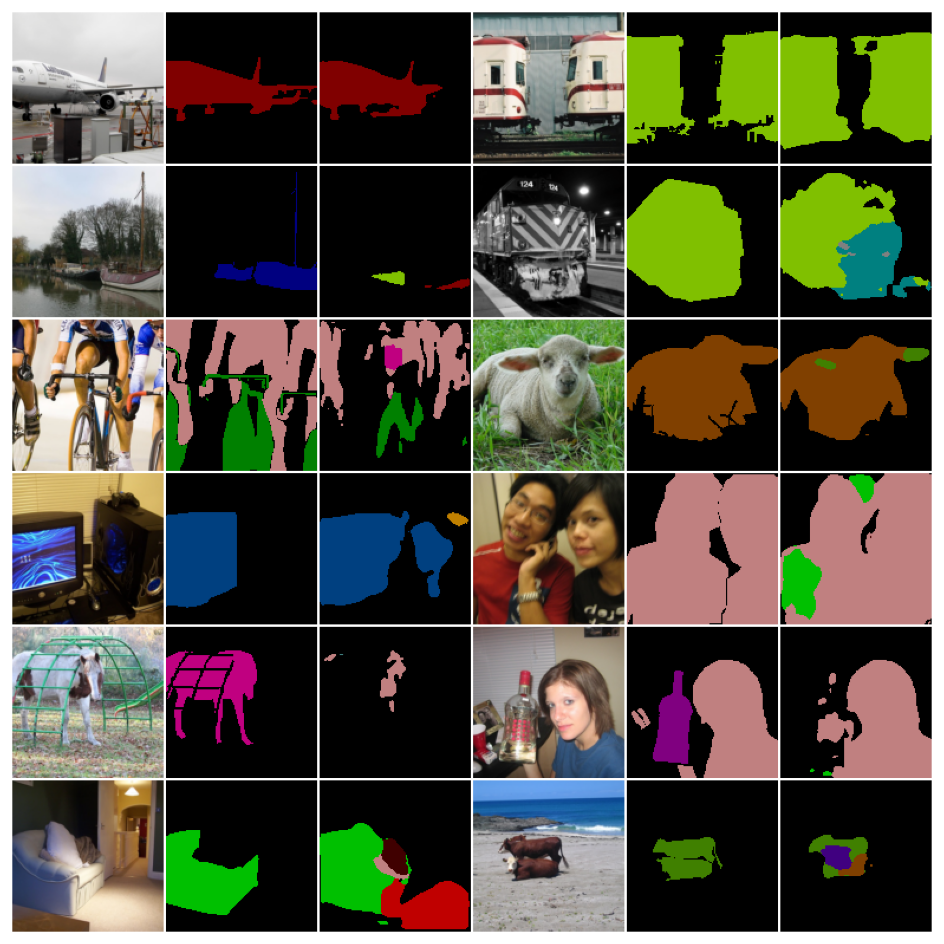

In [ ]:
from deepul_helper.demos import show_segmentation
show_segmentation()

# Demo 5: Avoiding Trivial Representations in Self-Supervised Tasks

When designing a self-supervised learning task, it is important to make sure that no trivial solutions exists. In general, a learned solution is trivial if the model is able to successfully complete its task by taking advantage of low-level features. As a result, it doesn't learn a good representation so downstream performance is bad.

For example, in the jigsaw [[4]](https://arxiv.org/abs/1603.09246) task, a model can "cheat" by just looking at the boundary textures of the jigsaw pieces, or following and matching straight lines across different pieces. These issues can generally be fixed by ranndom cropping, shifting, and spacially jittering.

We look at two other less obvious aspects of images that may reduce performance.

## Chromatic Aberration

Chromatic aberration occurs when the different focal lengths of light results in the light not meeting all at the same point.
![from wikipedia](https://drive.google.com/uc?id=1PYGoQWnH0aAeiE_8t4ef5WDcq1UIQQ5t)

A example of very apparent chromatic aberration is shown below, where the green and magenta colors are clearly offset with each other:

![](https://drive.google.com/uc?id=1M1B6kV6ddBwyJse3FQT8_XBTeqs5s5WL)

Chromatic aberration generally becomes a problem in patch-based self-supervised learning tasks that design, such as solving jigsaw puzzles, or predicintg the correct location of a patch in an image In this case, the model can take advantage of the low-level chromatic aberration features to get a strong idea of where the patch is located without understanding the actual context.

Below is a quick demo of chromatic aberration in more realistic images, and possible fixes. Note that in general, chromatic aberration is fairly hard to spot with the naked eye, but deep learning models are still able to use it to their advantage.

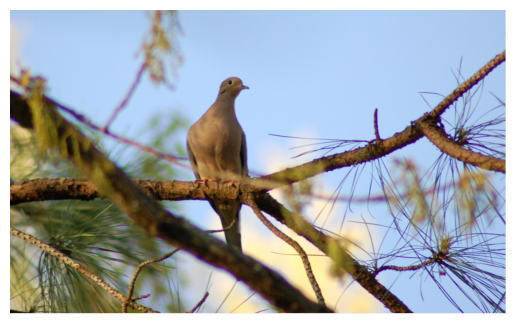

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

# You can see some chromatic aberration in the purple fringes around the branches

image = Image.open('sample_images/chrom_ab_demo.png')
plt.figure()
plt.axis('off')
plt.imshow(image)
plt.show()

Chromatic aberration is generally fixed through conversion to grayscale, or color dropping. Color dropping works by dropping 2 of the color channels and replacing them with random noise uniform or Gaussian noise.

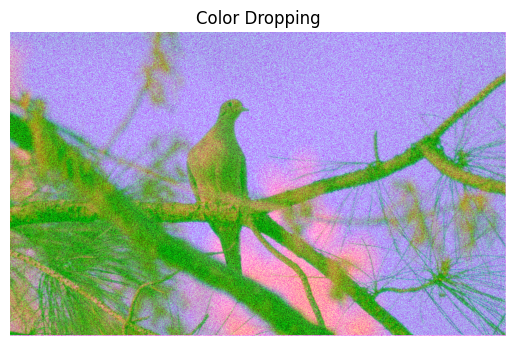

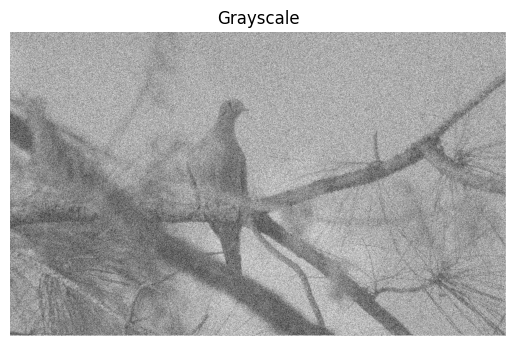

In [ ]:
import numpy as np

# Color Dropping
# We will drop all channels except R
image_cpy = image.copy()
pixels = image_cpy.load()

arr = np.array(image_cpy)
std_R = np.std(arr[:, :, 0])
mean_G, mean_B = np.mean(arr[:, :, 1]), np.mean(arr[:, :, 2])

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j] # (R, G, B, A)
    R, A = p[0], p[3]
    G = int(np.random.randn() * std_R + mean_G)
    B = int(np.random.randn() * std_R + mean_B)
    pixels[i, j] = (R, G, p[2], p[3])

plt.figure()
plt.title('Color Dropping')
plt.axis('off')
plt.imshow(image_cpy)
plt.show()

# Grayscale
image_cpy2 = image.copy()
pixels2 = image_cpy2.load()

for i in range(image.size[0]):
  for j in range(image.size[1]):
    p = pixels[i, j]
    G = int(0.3 * p[0] + 0.59 * p[1] + 0.11 * p[2])
    pixels2[i, j] = (G, G, G, 255)

plt.figure()
plt.title('Grayscale')
plt.axis('off')
plt.imshow(image_cpy2)
plt.show()

## Color Intensity Histograms

In the SimCLR paper, the authors show that the histogram of color intensities of different patches within the same image have very similar histograms, which may degrade training by encouraging models to look at low-level (pixel intensity) features to solve self-supervised tasks that involve matching positive patches of the same image.

Below, we run a similar demo to what was demonstrated in the paper

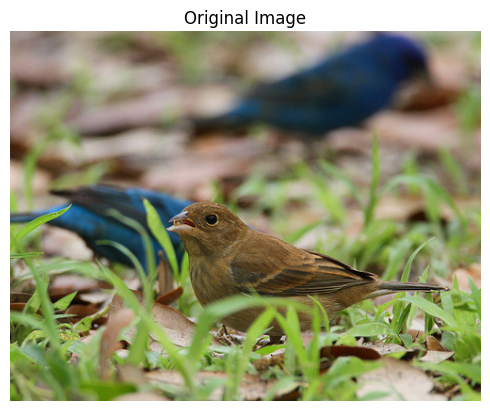

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Original Image')
plt.axis('off')
plt.imshow(image)
plt.show()

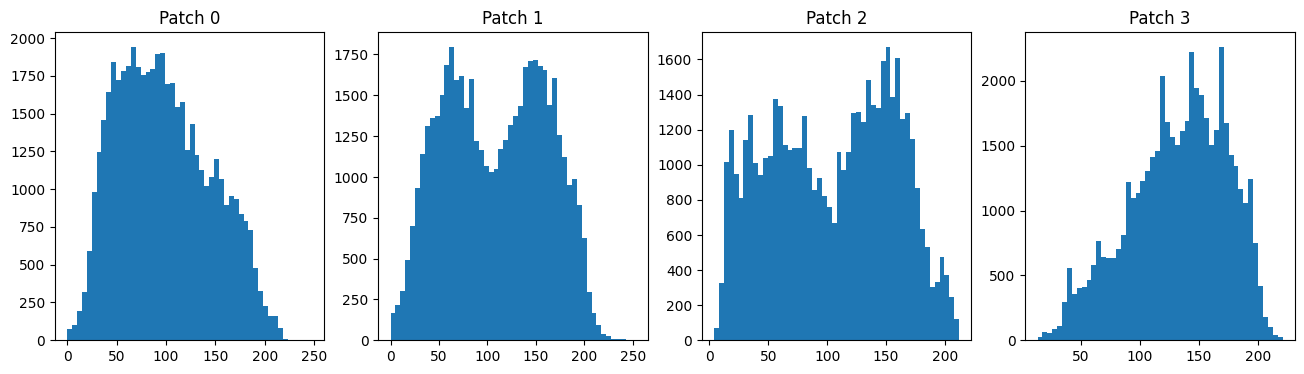

In [ ]:
import numpy as np
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

Now we apply color jittering to mitigate this effect

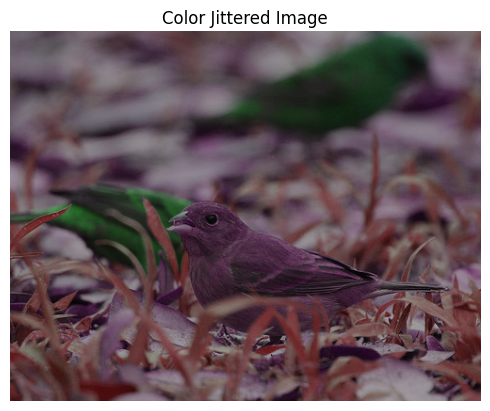

In [ ]:
from torchvision import transforms

color_jitter = transforms.ColorJitter(0.3, 0.3, 0.3, 0.3)
jitter_img = color_jitter(image)

image = Image.open('sample_images/n01537544_19414.JPEG')
plt.figure()
plt.title('Color Jittered Image')
plt.axis('off')
plt.imshow(jitter_img)
plt.show()

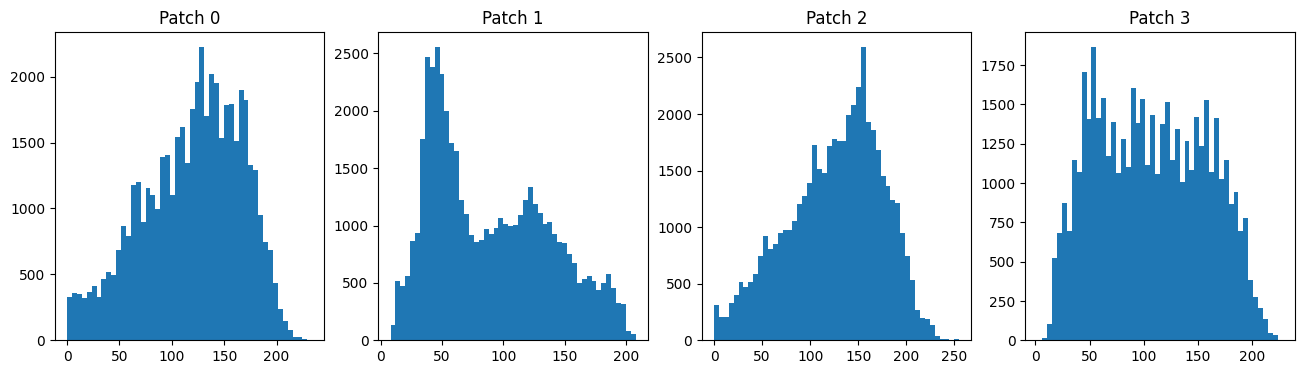

In [ ]:
arr = np.array(image)
H, W, _ = arr.shape

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
  r = np.random.randint(0, H - 128)
  c = np.random.randint(0, W - 128)
  patch = arr[r:r+128, c:c+128]

  axs[i].set_title(f'Patch {i}')
  axs[i].hist(patch.reshape(-1), bins=50)
plt.show()

## PREDICT PATCH POSITION

In [6]:
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(42)
S, P, GAP, JIT = 64, 14, 7, 1
STRIDE = P + GAP
MARGIN = (S - (3*P + 2*GAP)) // 2
OFFS = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]  # 8 pos

MEAN = torch.tensor([0.4914,0.4822,0.4465]).view(1,3,1,1)
STD  = torch.tensor([0.247,0.243,0.261]).view(1,3,1,1)
EPOCHS = 30

def prep(x):
    x = F.interpolate(x, size=S, mode="bilinear", align_corners=False)
    return (x - MEAN.to(x.device)) / STD.to(x.device)

def color_drop(p, std_R, mean_G, mean_B):
    R = p[:, 0:1]
    G = torch.randn_like(R) * std_R + mean_G
    B = torch.randn_like(R) * std_R + mean_B
    return torch.cat([R, G, B], dim=1)

def make_pairs(x):
    B = x.size(0); dev = x.device
    lab = torch.randint(0, 8, (B,), device=dev)
    offs = torch.tensor(OFFS, device=dev)[lab]
    jit = torch.randint(-JIT, JIT+1, (B, 2, 2), device=dev)
    base_c = MARGIN + STRIDE
    cy = base_c + jit[:,0,0]; cx = base_c + jit[:,0,1]
    ny = base_c + offs[:,0]*STRIDE + jit[:,1,0]
    nx = base_c + offs[:,1]*STRIDE + jit[:,1,1]
    ar = torch.arange(P, device=dev)
    def crop(y0, x0):
        iy = (y0[:,None] + ar)[:, :, None].expand(B, P, P)
        ix = (x0[:,None] + ar)[:, None, :].expand(B, P, P)
        bi = torch.arange(B, device=dev)[:,None,None].expand(B,P,P)
        return x.permute(0,2,3,1)[bi, iy, ix].permute(0,3,1,2)      # Bx3xPxP
    a, b = crop(cy, cx), crop(ny, nx)
    std_R  = x[:, 0:1].std(dim=(1,2,3), keepdim=True)
    mean_G = x[:, 1:2].mean(dim=(1,2,3), keepdim=True)
    mean_B = x[:, 2:3].mean(dim=(1,2,3), keepdim=True)
    return color_drop(a, std_R, mean_G, mean_B), color_drop(b, std_R, mean_G, mean_B), lab


class RelativePosition(nn.Module):
    def __init__(self, fc6=1024, fc7=512, n_pos=8):
        super().__init__()
        def cb(i, o, pool=False):
            L = [nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]
            if pool: L.append(nn.MaxPool2d(2))
            return L
        self.conv = nn.Sequential(*cb(3,64,True), *cb(64,192,True), *cb(192,384),
                                  *cb(384,256), *cb(256,256))        # 14->7->3 : 256x3x3
        self.fc6 = nn.Sequential(nn.Flatten(), nn.Linear(256*3*3, fc6),
                                 nn.BatchNorm1d(fc6), nn.ReLU(inplace=True))
        self.head = nn.Sequential(nn.Linear(2*fc6, fc7), nn.BatchNorm1d(fc7), nn.ReLU(inplace=True),
                                  nn.Dropout(0.3), nn.Linear(fc7, n_pos))
    def embed(self, p): return self.fc6(self.conv(p))
    def forward(self, a, b): return self.head(torch.cat([self.embed(a), self.embed(b)], 1))
    @torch.no_grad()
    def encode_image(self, x):
        return F.adaptive_avg_pool2d(self.conv(x), 4).flatten(1)     # 256*4*4 = 4096                       # 256*4*4 = 4096

tf = T.Compose([T.RandomHorizontalFlip(), T.ToTensor()])
tr10 = torchvision.datasets.CIFAR10("./data", True, transform=tf, download=True)
pre_loader = DataLoader(tr10, batch_size=64, shuffle=True, num_workers=0, drop_last=True)

model = RelativePosition().to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=EPOCHS*len(pre_loader))

for ep in range(EPOCHS):
    model.train(); tl = ta = n = 0
    for x, _ in pre_loader:
        a, b, y = make_pairs(prep(x.to(DEVICE)))
        out = model(a, b); loss = F.cross_entropy(out, y)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        tl += loss.item()*len(y); ta += (out.argmax(1)==y).sum().item(); n += len(y)
    print(f"epoch {ep+1:02d}  loss {tl/n:.4f}  pretext acc {100*ta/n:.2f}%")
torch.save(model.state_dict(), "patch_position_cifar10.pt")


@torch.no_grad()
def extract(loader):
    model.eval(); X, Y = [], []
    for x, y in loader:
        X.append(model.encode_image(prep(x.to(DEVICE))).cpu()); Y.append(y)
    return torch.cat(X), torch.cat(Y)

def linear_probe(name, cls, n_classes, epochs=30):
    t = T.ToTensor()
    trl = DataLoader(cls("./data", True, transform=t, download=True), batch_size=64, num_workers=0)
    tel = DataLoader(cls("./data", False, transform=t, download=True), batch_size=64, num_workers=0)
    Xtr, Ytr = extract(trl); Xte, Yte = extract(tel)
    m, s = Xtr.mean(0), Xtr.std(0)+1e-6; Xtr, Xte = (Xtr-m)/s, (Xte-m)/s
    clf = nn.Linear(Xtr.size(1), n_classes).to(DEVICE)
    o = torch.optim.Adam(clf.parameters(), 1e-3, weight_decay=1e-5)
    Xtr, Ytr = Xtr.to(DEVICE), Ytr.to(DEVICE)
    for ep in range(epochs):
        perm = torch.randperm(len(Xtr), device=DEVICE)
        for i in range(0, len(Xtr), 512):
            idx = perm[i:i+512]
            l = F.cross_entropy(clf(Xtr[idx]), Ytr[idx]); o.zero_grad(); l.backward(); o.step()
    with torch.no_grad():
        def acc(X, Y):
            lg = clf(X.to(DEVICE)); Y = Y.to(DEVICE)
            t1 = (lg.argmax(1)==Y).float().mean().item()*100
            t5 = (lg.topk(5,1).indices==Y[:,None]).any(1).float().mean().item()*100
            return t1, t5
        print(f"{name}: train top1/top5 = {acc(Xtr,Ytr)}, test top1/top5 = {acc(Xte,Yte)}")

linear_probe("CIFAR-10", torchvision.datasets.CIFAR10, 10)
linear_probe("CIFAR-100", torchvision.datasets.CIFAR100, 100)

epoch 01  loss 2.0609  pretext acc 17.74%
epoch 02  loss 1.9785  pretext acc 22.35%
epoch 03  loss 1.9289  pretext acc 25.08%
epoch 04  loss 1.8966  pretext acc 26.74%
epoch 05  loss 1.8710  pretext acc 28.32%
epoch 06  loss 1.8363  pretext acc 29.71%
epoch 07  loss 1.8013  pretext acc 31.23%
epoch 08  loss 1.7859  pretext acc 32.00%
epoch 09  loss 1.7595  pretext acc 33.41%
epoch 10  loss 1.7421  pretext acc 34.07%
epoch 11  loss 1.7298  pretext acc 34.59%
epoch 12  loss 1.7129  pretext acc 35.31%
epoch 13  loss 1.6924  pretext acc 36.37%
epoch 14  loss 1.6755  pretext acc 37.22%
epoch 15  loss 1.6650  pretext acc 37.35%
epoch 16  loss 1.6521  pretext acc 38.10%
epoch 17  loss 1.6311  pretext acc 39.08%
epoch 18  loss 1.6176  pretext acc 39.67%
epoch 19  loss 1.6018  pretext acc 40.00%
epoch 20  loss 1.5913  pretext acc 40.81%
epoch 21  loss 1.5672  pretext acc 41.63%
epoch 22  loss 1.5590  pretext acc 41.78%
epoch 23  loss 1.5462  pretext acc 42.63%
epoch 24  loss 1.5424  pretext acc